# Практическое занятие №7: Адаптивная фильтрация и частотно-временной анализ

## Подготовка окружения

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import ShortTimeFFT
from scipy.signal.windows import hann, gaussian, triang, boxcar
from scipy.io import wavfile
from IPython.display import Audio, display
from pathlib import Path

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

In [2]:
data_dir = Path('data') if Path('data').is_dir() else Path('../data')

def snr(clean, estimate):
    return 10*np.log10(np.sum(clean**2) / np.sum((estimate-clean)**2))

## Часть 1. Адаптивные фильтры

### Задание 1.1. Алгоритм LMS: идентификация неизвестной системы

#### Цель
Реализовать алгоритм LMS и с его помощью восстановить импульсную характеристику неизвестной системы.

#### Задание
1. «Неизвестная» система – КИХ-фильтр `h = signal.firwin(16, 0.3)`. Входной сигнал `x` – белый шум длиной 3000 отсчётов (`np.random.randn`). Желаемый сигнал – выход системы с небольшим шумом измерений: `d = signal.lfilter(h, 1, x) + 0.01*np.random.randn(len(x))`.
2. Допишите функцию `lms(x, d, N, mu)`: на каждом шаге вычисляется выход $y[n] = \mathbf{w}^T\mathbf{x}[n]$, ошибка $e[n] = d[n] - y[n]$ и обновляются коэффициенты $\mathbf{w} \leftarrow \mathbf{w} + \mu\,e[n]\,\mathbf{x}[n]$.
3. Запустите LMS с `N = 16`, `mu = 0.01`. Постройте **кривую обучения** – $10\lg e^2[n]$, сглаженную скользящим средним по 50 отсчётам.
4. Сравните найденные коэффициенты `w` с `h` на одном графике (`plt.stem`).

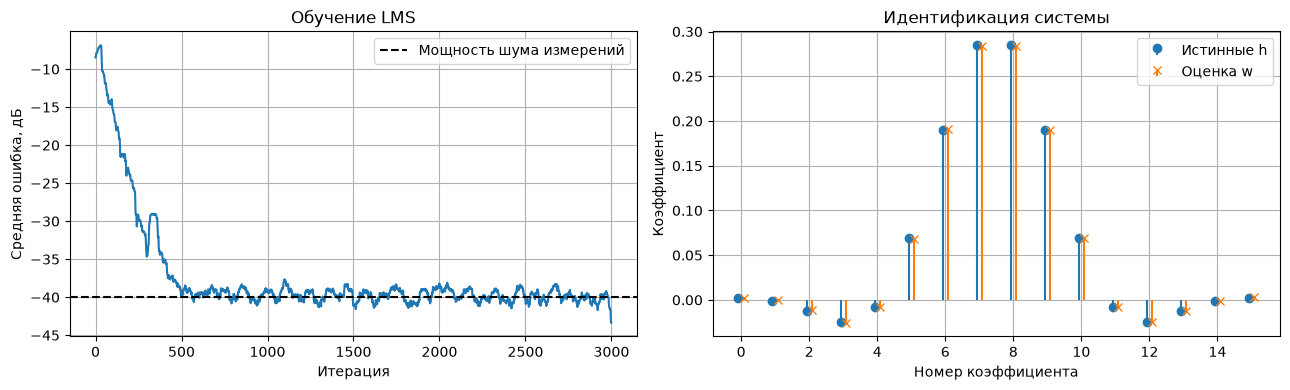

RMSE коэффициентов: 0.0006296869920141457
MSE на последних 500 отсчётах: 0.00010103970680585816


In [3]:
def lms(x, d, N, mu):
    w = np.zeros(N)
    e = np.zeros(len(x))
    padded = np.pad(x, (N-1, 0))
    for n in range(len(x)):
        x_vec = padded[n:n+N][::-1]
        y = w @ x_vec
        e[n] = d[n] - y
        w += mu * e[n] * x_vec
        if abs(e[n]) > 1e6:  # слишком большой шаг, обучение разошлось
            e[n:] = np.inf
            break
    return w, e

def learning_curve(e, L=50):
    return 10*np.log10(np.convolve(e**2, np.ones(L)/L, mode='same') + 1e-20)

np.random.seed(0)
h = signal.firwin(16, 0.3)
x_id = np.random.randn(3000)
d_id = signal.lfilter(h, 1, x_id) + 0.01*np.random.randn(len(x_id))
w_id, e_id = lms(x_id, d_id, 16, 0.01)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(learning_curve(e_id))
ax[0].axhline(-40, color='k', ls='--', label='Мощность шума измерений')
ax[0].set(xlabel='Итерация', ylabel='Средняя ошибка, дБ', title='Обучение LMS')
ax[0].legend()
n = np.arange(len(h))
ax[1].stem(n-0.08, h, linefmt='C0-', markerfmt='C0o', basefmt=' ', label='Истинные h')
ax[1].stem(n+0.08, w_id, linefmt='C1-', markerfmt='C1x', basefmt=' ', label='Оценка w')
ax[1].set(xlabel='Номер коэффициента', ylabel='Коэффициент', title='Идентификация системы')
ax[1].legend(); plt.tight_layout(); plt.show()
print('RMSE коэффициентов:', np.sqrt(np.mean((w_id-h)**2)))
print('MSE на последних 500 отсчётах:', np.mean(e_id[-500:]**2))

**Вопросы:**
- Через сколько итераций ошибка выходит на установившийся уровень? Чем определяется этот уровень?
- Насколько точно восстановлены коэффициенты неизвестной системы?

У меня ошибка выходит примерно на постоянный уровень после 500–700 отсчётов. MSE около 0,0001, почти как дисперсия шума измерений. Найденные коэффициенты почти совпали с исходными. Здесь фильтру удобно: вход белый, а длину мы взяли правильную.

### Задание 1.2. Выбор шага адаптации

1. Повторите задание 1.1 для `mu = 0.001, 0.01, 0.05, 0.1, 0.12, 0.15`. Постройте кривые обучения на одном графике.
2. Найдите экспериментально наибольшее значение `mu`, при котором алгоритм ещё сходится. Сравните его с оценкой $\mu_{\max} \approx \dfrac{2}{N\sigma_x^2}$, где $\sigma_x^2$ – дисперсия входного сигнала.
3. Увеличьте дисперсию входного сигнала в 4 раза (умножьте `x` на 2) и снова найдите порог устойчивости.

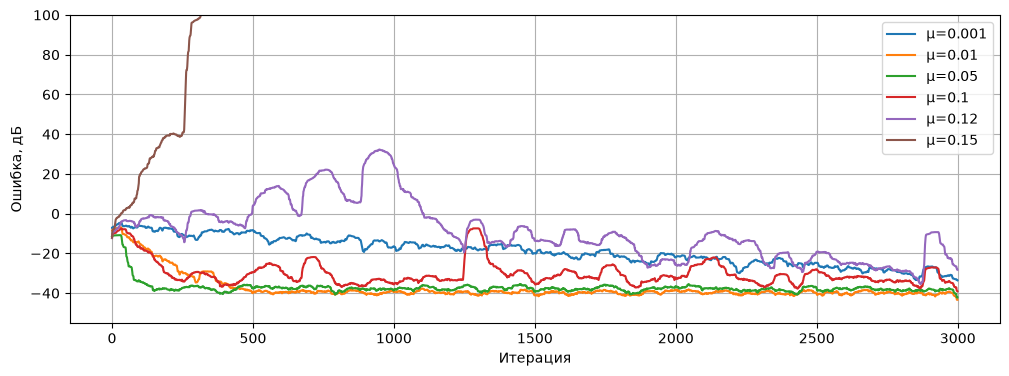

Множитель входа: 1 наибольший проверенный шаг: 0.11 оценка по формуле: 0.1328


Множитель входа: 2 наибольший проверенный шаг: 0.0275 оценка по формуле: 0.0332


In [4]:
for mu in [0.001, 0.01, 0.05, 0.1, 0.12, 0.15]:
    w, e = lms(x_id, d_id, 16, mu)
    plt.plot(learning_curve(e), label=f'μ={mu}')
plt.ylim(-55, 100)
plt.xlabel('Итерация')
plt.ylabel('Ошибка, дБ')
plt.legend()
plt.show()
for scale in [1, 2]:
    x = scale*x_id
    d = signal.lfilter(h, 1, x) + (d_id-signal.lfilter(h, 1, x_id))
    good = []
    for mu in np.arange(0.01, 0.151, 0.01)/scale**2:
        w, e = lms(x, d, 16, mu)
        if np.mean(e[-500:]**2) < 0.01:
            good.append(mu)
    print('Множитель входа:', scale, 'наибольший проверенный шаг:', max(good),
          'оценка по формуле:', round(2/(16*np.var(x)), 4))

**Вопросы:**
- Как шаг адаптации влияет на скорость сходимости и на установившуюся ошибку?
- Совпал ли найденный порог устойчивости с оценкой? Как он изменился при увеличении мощности входного сигнала?

Маленький шаг обучается медленно, большой быстрее, но с большей остаточной ошибкой. При 0,15 алгоритм расходится. По грубой сетке подходит шаг около 0,11; формула даёт около 0,13, то есть это ориентир с запасом, а не точная граница. После умножения входа на 2 мощность выросла вчетверо, и допустимый шаг стал примерно вчетверо меньше.

### Задание 1.3. NLMS при меняющейся мощности входного сигнала

1. Сформируйте вход с медленно меняющейся мощностью: `x = 3*np.random.randn(3000)*(1 + 0.9*np.sin(2*np.pi*np.arange(3000)/500))` и желаемый сигнал `d = signal.lfilter(h, 1, x)`.
2. Подберите наибольший шаг `mu`, при котором обычный LMS ещё устойчив.
3. Реализуйте NLMS: шаг нормируется на энергию вектора входных отсчётов, $\mathbf{w} \leftarrow \mathbf{w} + \dfrac{\mu}{\|\mathbf{x}[n]\|^2 + \varepsilon}\,e[n]\,\mathbf{x}[n]$, с `mu = 0.5`, `eps = 1e-6`.
4. Сравните кривые обучения LMS и NLMS.

Максимальный прошедший проверку шаг LMS на сетке: 0.0050
Нормы ошибки коэффициентов LMS, NLMS: 0.00010694676061924787 5.784124598161624e-17


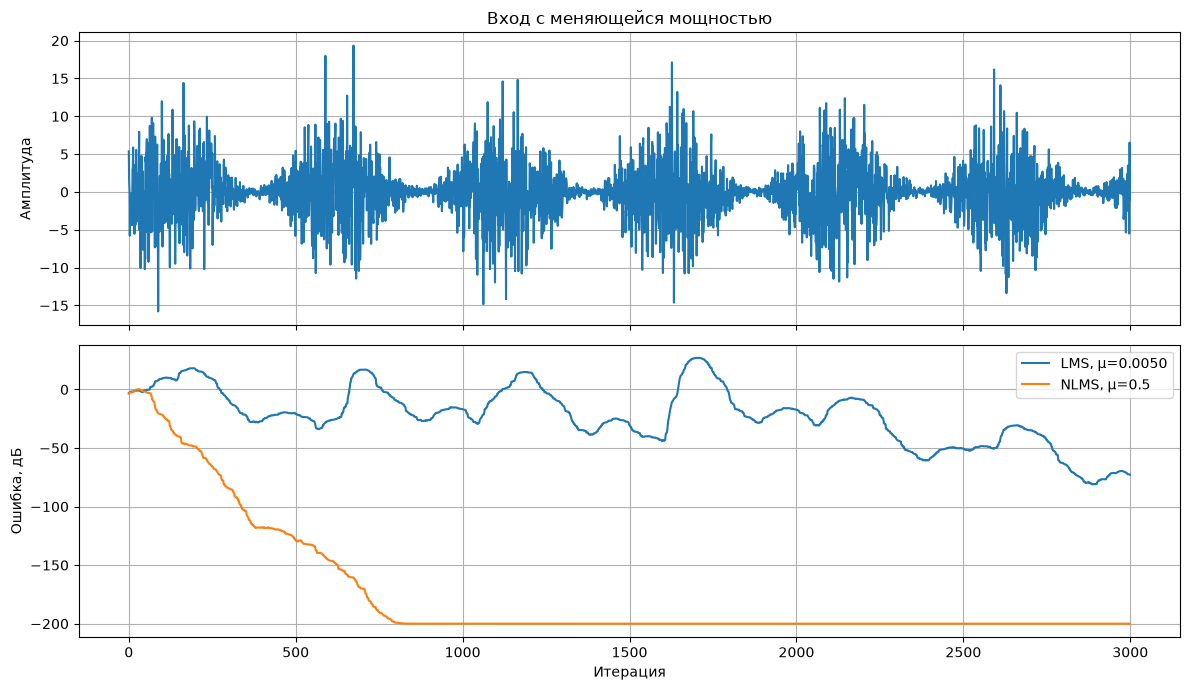

In [5]:
def nlms(x, d, N, mu, eps=1e-6):
    w = np.zeros(N)
    e = np.zeros(len(x))
    padded = np.pad(x, (N-1, 0))
    for n in range(len(x)):
        x_vec = padded[n:n+N][::-1]
        e[n] = d[n] - w @ x_vec
        w += mu * e[n] * x_vec / (x_vec @ x_vec + eps)
    return w, e

np.random.seed(3)
x_var = 3*np.random.randn(3000)*(1+0.9*np.sin(2*np.pi*np.arange(3000)/500))
d_var = signal.lfilter(h, 1, x_var)
good = []
for mu in [0.001, 0.003, 0.005, 0.007]:
    w, e = lms(x_var, d_var, 16, mu)
    if np.mean(e[-500:]**2) < 0.01:
        good.append(mu)
mu_var = max(good)
w_l, e_l = lms(x_var, d_var, 16, mu_var)
w_n, e_n = nlms(x_var, d_var, 16, 0.5)
print(f'Максимальный прошедший проверку шаг LMS на сетке: {mu_var:.4f}')
print('Нормы ошибки коэффициентов LMS, NLMS:', np.linalg.norm(w_l-h), np.linalg.norm(w_n-h))
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(x_var); ax[0].set(ylabel='Амплитуда', title='Вход с меняющейся мощностью')
ax[1].plot(learning_curve(e_l), label=f'LMS, μ={mu_var:.4f}')
ax[1].plot(learning_curve(e_n), label='NLMS, μ=0.5')
ax[1].set(xlabel='Итерация', ylabel='Ошибка, дБ'); ax[1].legend()
plt.tight_layout(); plt.show()

**Вопросы:**
- Почему для LMS приходится выбирать шаг по самому громкому участку сигнала?
- Почему NLMS сходится быстрее при той же устойчивости? Какой диапазон значений `mu` допустим для NLMS?

Из проверенных шагов обычного LMS подошёл примерно 0,005. Его приходится выбирать по громкому участку На тихом участке такой шаг уже обучается медленнее. NLMS делит поправку на энергию входа, поэтому меньше зависит от громкости и сходится быстрее. Для него обычно берут $0<\mu<2$

### Задание 1.4. Адаптивное подавление шума

#### Цель
Воспроизвести схему активного шумоподавления: из сигнала микрофона вычитается оценка шума, полученная из опорного датчика.

#### Задание
1. Загрузите `fragment.wav`, переведите в моно (среднее каналов) и нормируйте в диапазон $[-1, 1]$. Это полезный сигнал `s`.
2. Опорный датчик регистрирует шум `ref = 0.5*np.random.randn(len(s))`. До микрофона этот шум доходит через неизвестный акустический тракт `path = signal.firwin(32, 0.2)`. Сигнал микрофона: `d = s + signal.lfilter(path, 1, ref)`.
3. Примените LMS (вход – `ref`, желаемый сигнал – `d`, `N = 32`, `mu = 0.002`). Оценкой полезного сигнала служит **сигнал ошибки** `e`.
4. Вычислите отношение сигнал/шум до и после обработки по формуле $\mathrm{SNR} = 10\lg\dfrac{\sum s^2}{\sum (\hat s - s)^2}$ (после обработки – по второй половине записи, когда фильтр уже сошёлся).
5. Прослушайте `d` и `e`. Повторите эксперимент с NLMS и с длиной фильтра `N = 8`.

SNR до обработки (вторая половина): -2.57 дБ


LMS32: SNR второй половины=21.75 дБ

C:\Users\n1\AppData\Local\Temp\ipykernel_49192\490176030.py:1: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, s = wavfile.read(data_dir / 'fragment.wav')


NLMS32: SNR второй половины=13.34 дБ


LMS8: SNR второй половины=-2.58 дБ


NLMS8: SNR второй половины=-2.97 дБ


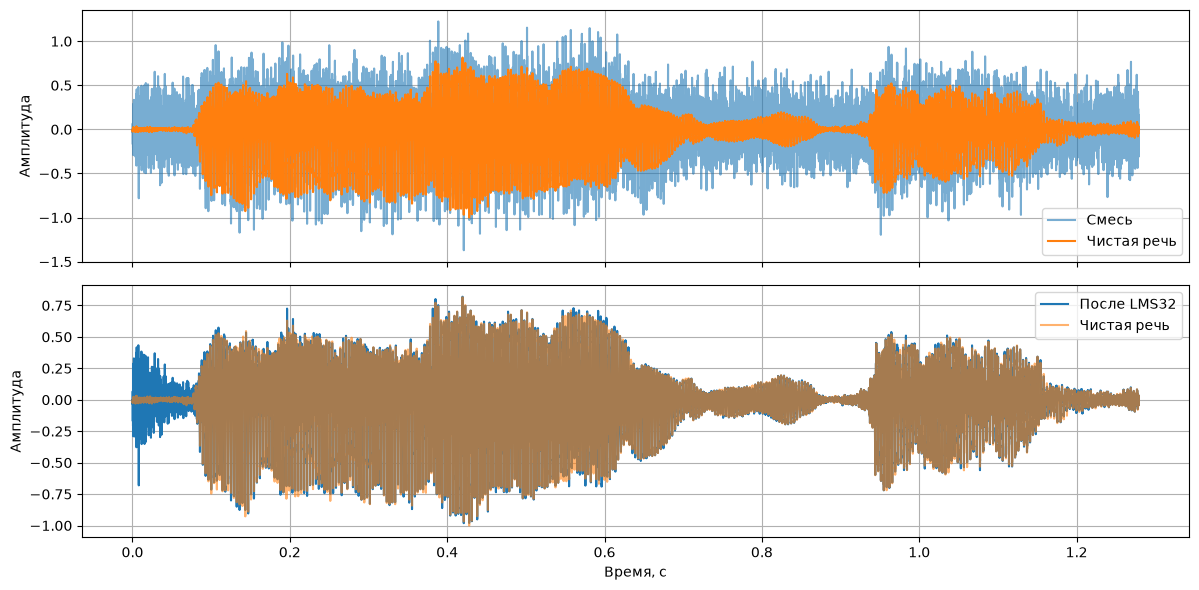

Исходная речь


Смесь


LMS32


NLMS32


In [6]:
fs, s = wavfile.read(data_dir / 'fragment.wav')
s = s.mean(axis=1)
s /= np.max(np.abs(s))
np.random.seed(1)
ref = 0.5*np.random.randn(len(s))
path = signal.firwin(32, 0.2)
d = s + signal.lfilter(path, 1, ref)
half = slice(len(s)//2, None)
cleaned = {}
print(f'SNR до обработки (вторая половина): {snr(s[half], d[half]):.2f} дБ')
for name, method, length, mu in [('LMS32', lms, 32, 0.002), ('NLMS32', nlms, 32, 0.1),
                                  ('LMS8', lms, 8, 0.002), ('NLMS8', nlms, 8, 0.1)]:
    ww, ee = method(ref, d, length, mu)
    cleaned[name] = ee
    print(f'{name}: SNR второй половины={snr(s[half], ee[half]):.2f} дБ')
tt = np.arange(len(s))/fs
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(tt, d, alpha=0.6, label='Смесь'); ax[0].plot(tt, s, label='Чистая речь'); ax[0].legend()
ax[1].plot(tt, cleaned['LMS32'], label='После LMS32'); ax[1].plot(tt, s, alpha=0.6, label='Чистая речь')
ax[1].legend(); ax[1].set_xlabel('Время, с')
for a in ax: a.set_ylabel('Амплитуда')
plt.tight_layout(); plt.show()
playback_scale = max(np.max(abs(y)) for y in [s, d, cleaned['LMS32'], cleaned['NLMS32']])
for name, y in [('Исходная речь', s), ('Смесь', d), ('LMS32', cleaned['LMS32']), ('NLMS32', cleaned['NLMS32'])]:
    print(name); display(Audio(y/playback_scale, rate=fs, normalize=False))

**Вопросы:**
- Почему сигнал ошибки адаптивного фильтра оказывается очищенной речью?
- Что произойдёт, если опорный датчик будет улавливать и полезный сигнал?
- Как результат зависит от соотношения длины фильтра и длины импульсной характеристики акустического тракта?

Фильтр получает опорный шум и учится повторять, как тот дошёл до микрофона. После вычитания оценки шума у нас остаётся речь, поэтому нужен сигнал ошибки e. LMS с длиной 32 заметно улучшил SNR, NLMS тоже помог.

Если в опорный канал попадёт речь, мы начнём вычитать и её. А длины 8 не хватает, чтобы повторить тракт из 32 коэффициентов, поэтому результат хуже. Для плееров я взял общий масштаб громкости, чтобы сравнение было понятнее.

### Задание 1.5. Фильтр Калмана и экспоненциальное сглаживание

1. Смоделируйте случайное блуждание `true = np.cumsum(0.1*np.random.randn(500))` и его зашумлённые измерения `z = true + 0.5*np.random.randn(500)`.
2. Реализуйте скалярный фильтр Калмана с $F = H = 1$:
   - прогноз: $P^- = P + Q$;
   - коррекция: $K = \dfrac{P^-}{P^- + R}$, $\;\hat x \leftarrow \hat x + K(z - \hat x)$, $\;P = (1 - K)P^-$.

   Используйте $Q = 0.01$, $R = 0.25$, начальные $\hat x = 0$, $P = 1$. Постройте оценку и коэффициент $K$ как функцию номера шага.
3. Найдите установившееся значение $K_\infty$ и сравните его с аналитическим $K_\infty = \dfrac{-Q + \sqrt{Q^2 + 4QR}}{2R}$.
4. Примените к измерениям экспоненциальное сглаживание с $\alpha = K_\infty$ (лекция 5) и сравните с оценкой Калмана. Вычислите среднеквадратичные ошибки обеих оценок и самих измерений.
5. Повторите для $Q = 0.1$ и $Q = 0.001$ при том же $R$.

RMSE измерений: 0.4891251838284415
Q: 0.001 K: 0.0613 K по формуле: 0.0613 RMSE Калмана: 0.3014 RMSE сглаживания: 0.304
Q: 0.01 K: 0.181 K по формуле: 0.181 RMSE Калмана: 0.1896 RMSE сглаживания: 0.1894
Q: 0.1 K: 0.4633 K по формуле: 0.4633 RMSE Калмана: 0.2649 RMSE сглаживания: 0.2648


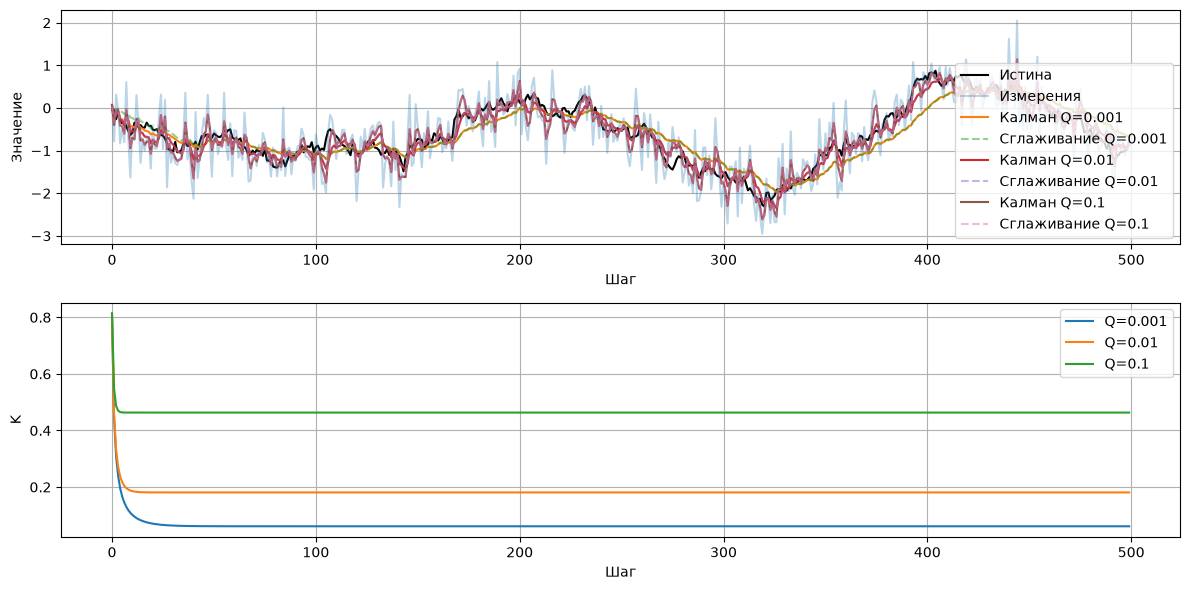

In [7]:
np.random.seed(2)
true = np.cumsum(0.1*np.random.randn(500))
z = true + 0.5*np.random.randn(500)
print('RMSE измерений:', np.sqrt(np.mean((z-true)**2)))
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(true, 'k', label='Истина')
axes[0].plot(z, alpha=0.3, label='Измерения')
for Q in [0.001, 0.01, 0.1]:
    R = 0.25
    xhat, P = 0, 1
    estimate, gains = [], []
    for value in z:
        P += Q
        K = P/(P+R)
        xhat += K*(value-xhat)
        P *= 1-K
        estimate.append(xhat)
        gains.append(K)
    K_inf = (-Q + np.sqrt(Q**2+4*Q*R))/(2*R)
    exponential = signal.lfilter([K_inf], [1, -(1-K_inf)], z)
    print('Q:', Q, 'K:', round(gains[-1], 4), 'K по формуле:', round(K_inf, 4),
          'RMSE Калмана:', round(np.sqrt(np.mean((np.array(estimate)-true)**2)), 4),
          'RMSE сглаживания:', round(np.sqrt(np.mean((exponential-true)**2)), 4))
    axes[0].plot(estimate, label=f'Калман Q={Q}')
    axes[0].plot(exponential, '--', alpha=0.5, label=f'Сглаживание Q={Q}')
    axes[1].plot(gains, label=f'Q={Q}')
axes[0].set(xlabel='Шаг', ylabel='Значение')
axes[1].set(xlabel='Шаг', ylabel='K')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:**
- Почему в установившемся режиме фильтр Калмана совпадает с экспоненциальным сглаживанием? В чём тогда преимущество фильтра Калмана?
- Как отношение $Q/R$ влияет на коэффициент $K$ и на гладкость оценки?

Установившийся K почти постоянный, и формула Калмана превращается в обычное экспоненциальное сглаживание с α=K. При Q=0,01 у меня K около 0,181, ошибки двух методов почти одинаковые. Калман ещё ведёт оценку неопределённости и может менять доверие к измерениям

## Часть 2. Частотно-временной анализ

### Задание 2.1. Спектрограмма и выбор длины окна

1. Сформируйте сигнал длительностью 2 с при $f_s = 1000$ Гц:
   - сумма двух тонов 100 и 110 Гц на интервале $0 \le t < 1$ с;
   - два коротких щелчка (одиночные отсчёты амплитуды 5) в моменты 1.50 и 1.53 с;
   - линейный чирп от 200 до 400 Гц на всей длительности (`signal.chirp`).
2. Постройте спектрограммы с окном Ханна длиной `Nw = 32, 128, 512` отсчётов и шагом `Nw//8` (класс `ShortTimeFFT`, см. заметки).
3. Для каждой длины окна определите, различимы ли тоны 100 и 110 Гц и различимы ли два щелчка.
4. Объясните результат с помощью оценок разрешения: по частоте $\Delta f \approx 2f_s/N_w$ (ширина главного лепестка окна Ханна), по времени $\Delta t \approx N_w/f_s$.

Nw=32: Δf≈62.50 Гц, Δt≈0.032 с
Nw=128: Δf≈15.62 Гц, Δt≈0.128 с
Nw=512: Δf≈3.91 Гц, Δt≈0.512 с


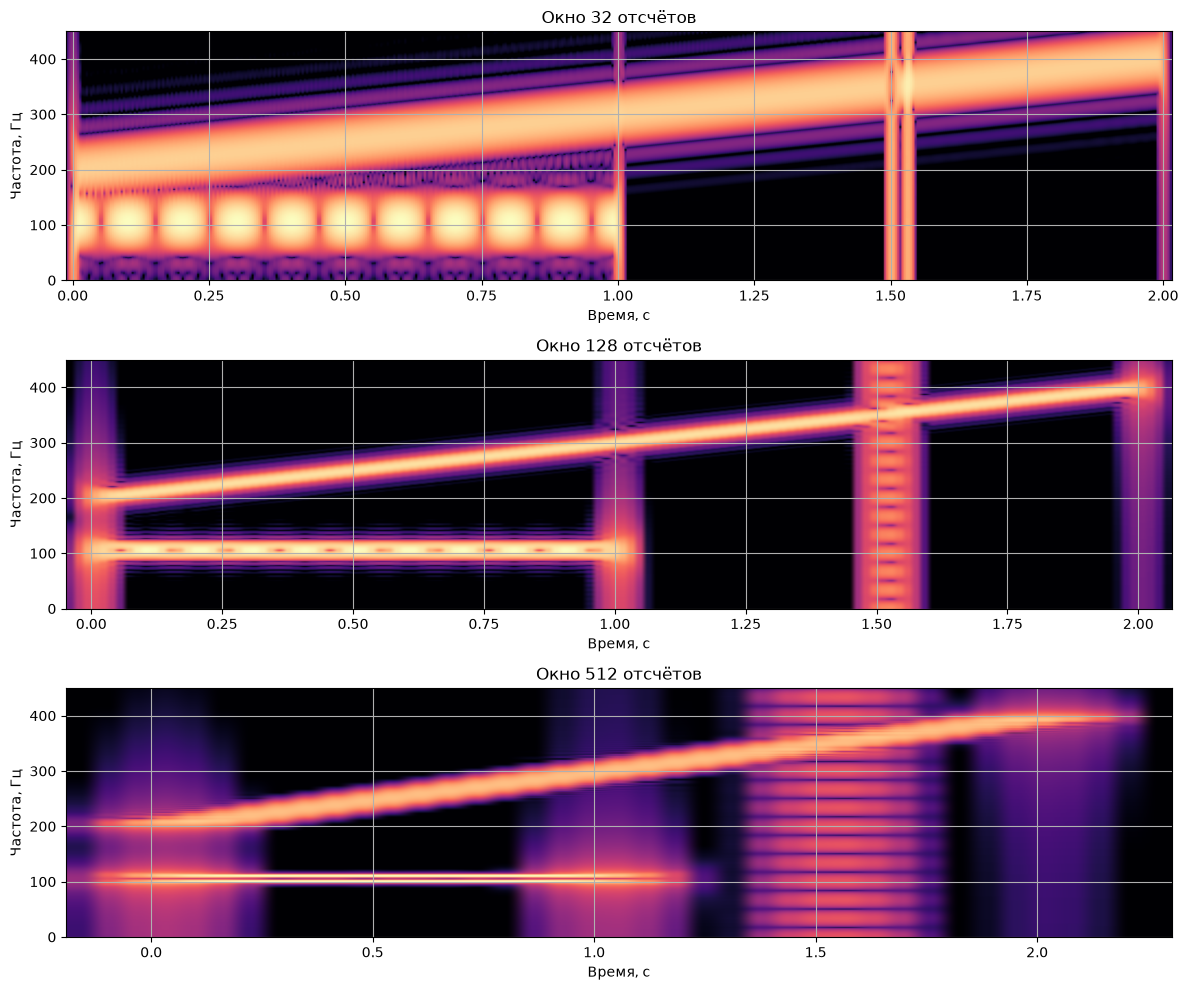

In [8]:
fs = 1000
t = np.arange(0, 2, 1/fs)
x_tf = (np.sin(2*np.pi*100*t)+np.sin(2*np.pi*110*t))*(t<1)
x_tf += signal.chirp(t, f0=200, f1=400, t1=2)
x_tf[int(1.50*fs)] += 5
x_tf[int(1.53*fs)] += 5

def show_spectrogram(x, fs, Nw, ax, fmax=None):
    SFT = ShortTimeFFT(hann(Nw, sym=False), hop=Nw//8, fs=fs, mfft=max(Nw, 1024))
    S = SFT.spectrogram(x)
    ax.imshow(10*np.log10(S+1e-12), origin='lower', aspect='auto', cmap='magma',
              extent=SFT.extent(len(x)), vmin=10*np.log10(S.max())-60)
    ax.set(xlabel='Время, с', ylabel='Частота, Гц', title=f'Окно {Nw} отсчётов')
    if fmax is not None: ax.set_ylim(0, fmax)
    return SFT, S

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for nw, ax in zip([32, 128, 512], axes):
    show_spectrogram(x_tf, fs, nw, ax, 450)
    print(f'Nw={nw}: Δf≈{2*fs/nw:.2f} Гц, Δt≈{nw/fs:.3f} с')
plt.tight_layout(); plt.show()

**Вопросы:**
- При какой длине окна разрешаются тоны 100 и 110 Гц? При какой – два щелчка? Можно ли подобрать окно, при котором разрешается и то, и другое?
- Как выглядит чирп на спектрограммах с разной длиной окна и почему?

 разделяю тоны при окне 512, а короткие щелчки лучше видны при 32. Окно 128 где-то посередине. Одним окном уверенно решить обе задачи у меня не вышло. Чирп выглядит наклонной полосой: короткое окно размывает её по частоте, а за длинное окно частота уже успевает измениться.

### Задание 2.2. Принцип неопределённости

Эффективные длительность и ширина спектра окна $w[n]$ определяются через вторые моменты распределений $|w[n]|^2$ и $|W(f)|^2$:
$$
\Delta t^2 = \frac{\sum_n (n - \bar n)^2 |w[n]|^2}{\sum_n |w[n]|^2}, \qquad
\Delta f^2 = \frac{\int f^2 |W(f)|^2 df}{\int |W(f)|^2 df}.
$$
1. Допишите функцию `widths(w)`, вычисляющую $\Delta t$ (в отсчётах) и $\Delta f$ (в циклах на отсчёт). Спектр вычисляйте через БПФ с большим дополнением нулями (`nfft = 2**18`).
2. Вычислите произведение $\Delta t\,\Delta f$ для гауссовых окон длины 256 с σ = 8, 16, 32, а также для окон Ханна, треугольного и прямоугольного той же длины.
3. Сравните результаты с нижней границей $1/(4\pi) \approx 0.0796$.

In [9]:
def widths(w, nfft=2**18):
    n = np.arange(len(w))
    power_t = np.abs(w)**2
    center = np.sum(n*power_t)/np.sum(power_t)
    dt = np.sqrt(np.sum((n-center)**2*power_t)/np.sum(power_t))
    freq = np.fft.fftfreq(nfft)
    power_f = np.abs(np.fft.fft(w, nfft))**2
    df = np.sqrt(np.sum(freq**2*power_f)/np.sum(power_f))
    return dt, df

M = 256
windows = {'Гаусс σ=8': gaussian(M, 8), 'Гаусс σ=16': gaussian(M, 16),
           'Гаусс σ=32': gaussian(M, 32), 'Ханн': hann(M),
           'Треугольное': triang(M), 'Прямоугольное': boxcar(M)}
print(f'{"Окно":20} {"Δt":>10} {"Δf":>12} {"Произведение":>14}')
for name, win in windows.items():
    dt, df = widths(win)
    print(f'{name:20} {dt:10.5f} {df:12.7f} {dt*df:14.7f}')
print('Нижняя граница:', 1/(4*np.pi))
print('Проверка сходимости для прямоугольника:')
for nfft in [2**10, 2**14, 2**18, 2**20]:
    dt, df = widths(boxcar(M), nfft)
    print(f'nfft={nfft}: ΔtΔf={dt*df:.8f}')

Окно                         Δt           Δf   Произведение
Гаусс σ=8               5.65685    0.0140674      0.0795775
Гаусс σ=16             11.31371    0.0070337      0.0795775
Гаусс σ=32             22.62741    0.0035169      0.0795779
Ханн                   36.06929    0.0022641      0.0816652
Треугольное            40.47746    0.0021486      0.0869707
Прямоугольное          73.90027    0.0165631      1.2240177
Нижняя граница: 0.07957747154594767
Проверка сходимости для прямоугольника:
nfft=1024: ΔtΔf=1.22401764
nfft=16384: ΔtΔf=1.22401773
nfft=262144: ΔtΔf=1.22401773
nfft=1048576: ΔtΔf=1.22401773


**Вопросы:**
- Какое окно ближе всего к нижней границе? Почему для гауссова окна с большим σ произведение отклоняется от границы?
- Почему у прямоугольного окна произведение получается большим и зависит от длины БПФ?

Гаусс ближе всего к $1/(4\pi)\approx0{,}0796$. Ханн и треугольное окно хуже. Если гаусс слишком широкий для массива, его хвосты обрезаются, и результат отходит от границы. У прямоугольного окна резкие края и сильные боковые лепестки, поэтому произведение гораздо больше. С ростом длины БПФ дискретная оценка сходится, а не растёт бесконечно.

### Задание 2.3. Спектрограмма музыкального фрагмента

1. Загрузите `sample-3s.wav`, переведите в моно и нормируйте.
2. Постройте осциллограмму и спектрограммы с окнами длиной 256 и 4096 отсчётов в диапазоне частот 0–4 кГц.
3. По спектрограмме с длинным окном оцените частоту основного тона ноты, звучащей около $t = 2.3$ с: найдите частоты нескольких гармоник и расстояние между ними. Уточните результат по амплитудному спектру участка длиной 8192 отсчёта (с окном Ханна).
4. Определите, какой ноте соответствует найденная частота (ля первой октавы – 440 Гц, соседние полутона отличаются в $2^{1/12}$ раз).

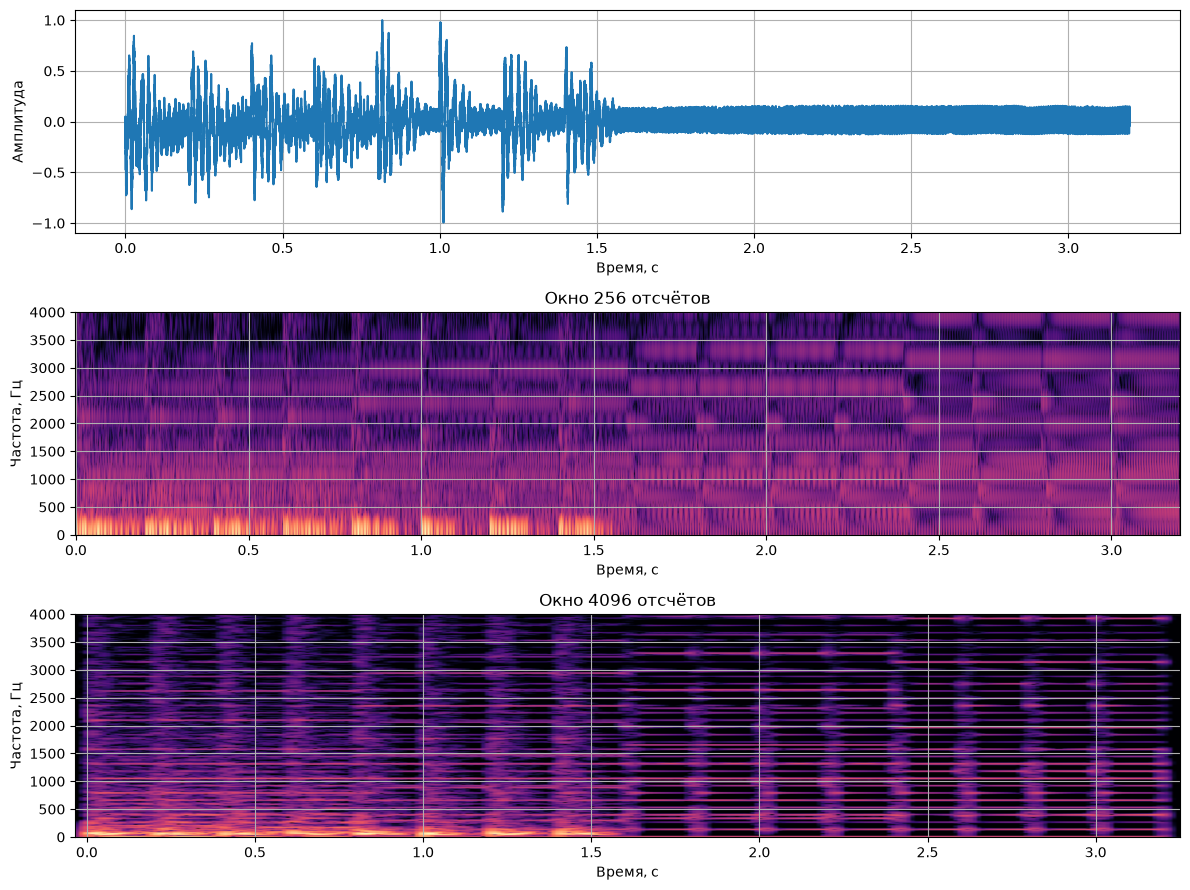

Пики до 1500 Гц: [ 129.2  263.8  328.4  393.   522.2  656.8  786.   915.2  990.5 1044.4
 1178.9 1308.1 1437.3]
Частота: 328.4 Гц, нота: ми MIDI: 64


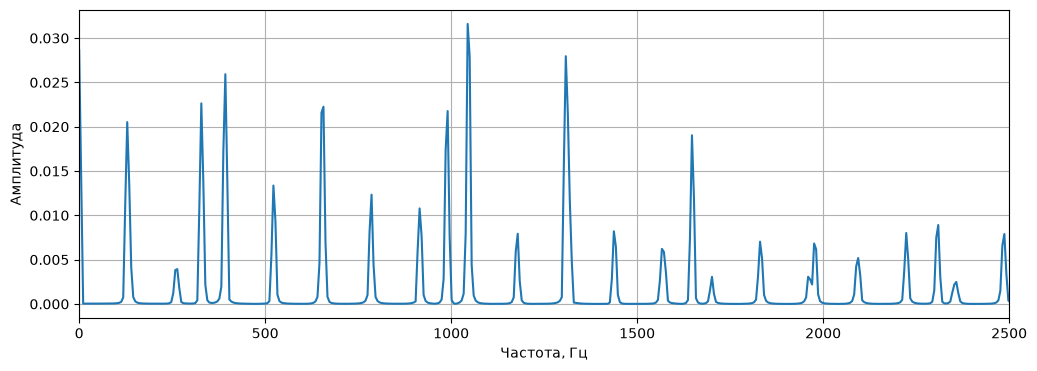

In [10]:
fs_a, audio = wavfile.read(data_dir / 'sample-3s.wav')
audio = audio.mean(axis=1)
audio -= audio.mean()
audio /= np.max(abs(audio))
t_audio = np.arange(len(audio))/fs_a
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(t_audio, audio)
axes[0].set(xlabel='Время, с', ylabel='Амплитуда')
show_spectrogram(audio, fs_a, 256, axes[1], 4000)
show_spectrogram(audio, fs_a, 4096, axes[2], 4000)
plt.tight_layout()
plt.show()
N = 8192
center = int(2.3*fs_a)
part = audio[center-N//2:center+N//2]
window = hann(N, sym=False)
amp = 2*abs(np.fft.rfft(part*window))/window.sum()
freq = np.fft.rfftfreq(N, 1/fs_a)
peaks, _ = signal.find_peaks(amp, prominence=amp.max()*0.025, distance=10)
print('Пики до 1500 Гц:', np.round(freq[peaks[freq[peaks] < 1500]], 1))
# По расстоянию между гармониками выбираю основной тон около 330 Гц.
peak = peaks[np.argmin(abs(freq[peaks]-330))]
f0 = freq[peak]
midi = int(round(69 + 12*np.log2(f0/440)))
notes = ['до', 'до♯', 'ре', 'ре♯', 'ми', 'фа', 'фа♯', 'соль', 'соль♯', 'ля', 'ля♯', 'си']
print('Частота:', round(f0, 1), 'Гц, нота:', notes[midi % 12], 'MIDI:', midi)
plt.plot(freq, amp)
plt.xlim(0, 2500)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда')
plt.show()
display(Audio(audio, rate=fs_a))

**Вопросы:**
- Что лучше видно на спектрограмме с коротким окном, а что – с длинным?
- Какова частота основного тона и какая это нота?

Короткое окно лучше показывает атаки, а длинное — отдельные гармоники. На участке около 2,3 с я вижу пики примерно на 328, 657, 991 и 1308 Гц. Расстояние между ними около 330 Гц, поэтому беру основной тон около 328 Гц. Это ми первой октавы, E4, рядом с обычными 329,63 Гц. Шаг сетки тут около 5,38 Гц, так что большей точности от этого пика не жду.

### Задание 2.4. Обработка в частотно-временной области

1. Добавьте к музыкальному фрагменту из задания 2.3 помеху – тон 3 кГц амплитудой 0.2, звучащий только на интервале от 1 до 2 с.
2. Вычислите STFT (`SFT.stft`) с окном Ханна длиной 1024 и шагом 256. Убедитесь, что обратное преобразование (`SFT.istft(X, k1=len(x))`) без изменений восстанавливает сигнал с точностью до ошибок округления.
3. Обнулите коэффициенты STFT в полосе 3000 ± 50 Гц на интервале 0.9–2.1 с и выполните обратное преобразование.
4. Сравните спектрограммы и прослушайте сигналы до и после обработки. Вычислите отношение сигнал/помеха до и после.
5. Попробуйте вместо этого убрать помеху обычным режекторным фильтром (`signal.iirnotch`). Чем отличается результат?

Максимальная ошибка STFT → iSTFT: 5.551115123125783e-16
SNR до: 6.66 дБ
SNR после маски: 28.99 дБ
SNR после notch: 30.92 дБ


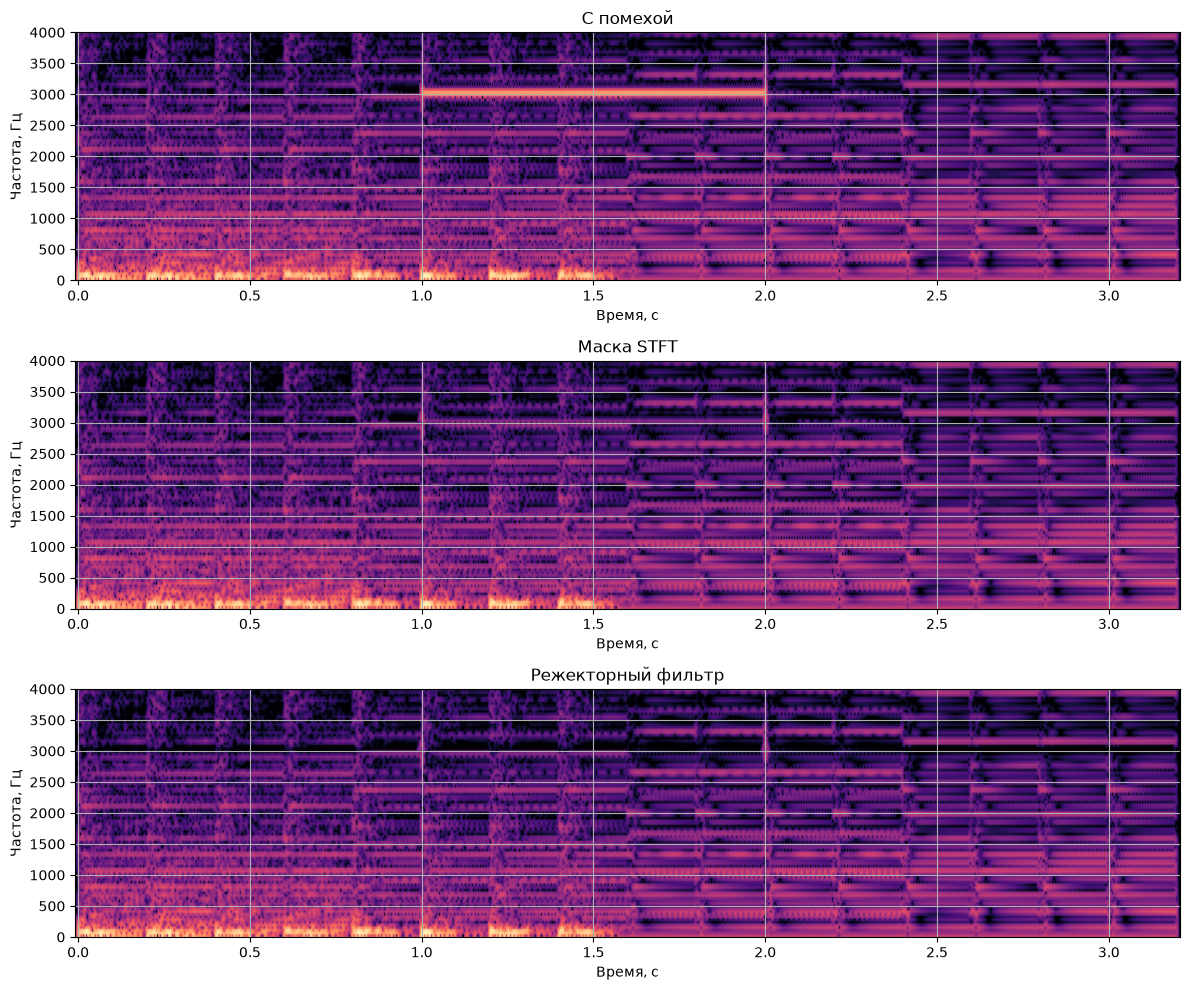

С помехой


После маски


После notch


In [11]:
interference = 0.2*np.sin(2*np.pi*3000*t_audio)*((t_audio>=1)&(t_audio<2))
noisy_audio = audio + interference
SFT = ShortTimeFFT(hann(1024, sym=False), hop=256, fs=fs_a)
X = SFT.stft(noisy_audio)
back = SFT.istft(X, k1=len(audio))
print('Максимальная ошибка STFT → iSTFT:', np.max(np.abs(back-noisy_audio)))
times = SFT.t(len(audio))
mask = ((np.abs(SFT.f[:, None]-3000)<=50)
        & (times[None, :]>=0.9)&(times[None, :]<=2.1))
X_clean = X.copy(); X_clean[mask] = 0
restored = SFT.istft(X_clean, k1=len(audio))
b_notch, a_notch = signal.iirnotch(3000, Q=30, fs=fs_a)
notched = signal.filtfilt(b_notch, a_notch, noisy_audio)
print(f'SNR до: {snr(audio, noisy_audio):.2f} дБ')
print(f'SNR после маски: {snr(audio, restored):.2f} дБ')
print(f'SNR после notch: {snr(audio, notched):.2f} дБ')
fig, ax = plt.subplots(3, 1, figsize=(12, 10))
for a, y, name in zip(ax, [noisy_audio, restored, notched], ['С помехой', 'Маска STFT', 'Режекторный фильтр']):
    show_spectrogram(y, fs_a, 1024, a, 4000); a.set_title(name)
plt.tight_layout(); plt.show()
for name, y in [('С помехой', noisy_audio), ('После маски', restored), ('После notch', notched)]:
    print(name); display(Audio(y, rate=fs_a))

**Вопросы:**
- Почему маску удалось ограничить и по частоте, и по времени? Что произойдёт с музыкой, если обнулить ту же полосу на всей длительности?
- Чем обработка в частотно-временной области лучше обычного режекторного фильтра для помехи, которая появляется на короткое время?

У STFT есть сразу время и частота, поэтому я могу убрать только нужный прямоугольник коэффициентов. Обратное преобразование без маски восстанавливает запись почти точно. Маска сильно улучшила SNR, но обычный notch в этом опыте дал даже чуть лучший общий результат. Зато маска не вырезает эту частоту на всей записи. Если обнулить полосу везде, мы потеряем часть музыки и там, где помехи не было.

## Вывод

Я увидел, что адаптивному фильтру нужен хороший опорный сигнал, а спектрограмме — подходящее окно. Ну и одного лучшего набора параметров тут нет: для коротких щелчков и близких тонов условия разные. Маска STFT удобна, когда помеха появляется только на части записи.